# Module 2 - Premium quote model

**Goal (from the brief):** predict the yearly motor-insurance premium from what the customer types into the quote form -
vehicle type, make and model, year, fuel, city, IDV and NCB - and explain every quote with SHAP.
On held-out data the model must reach **R2 above 0.85** and an **RMSE within Rs 2,000**.

This notebook follows the same steps as `python -m scripts.train_quote`, the script that writes the file the web page
loads (`models/quote_model.pkl`). Here every step is shown together with its output:

1. the data
2. five columns we must not use (they would leak the answer)
3. train / test split
4. feature engineering
5. training
6. results against the brief
7. what the five columns would do if the model could see them
8. why gradient boosting (compared with simpler methods)
9. which factors matter (taking one factor away at a time)
10. SHAP: explaining the model and single quotes
11. checking the saved `.pkl` file

Use **Run All**; it takes a few minutes. The notebook never writes to `models/` or `reports/`.

In [1]:
import inspect
import io
import os
import platform
import sys
import textwrap
import time
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", message="IProgress not found")      # a harmless notice from the progress bar inside shap

# Find the project folder (the one that holds the acko package), so the notebook also works when it is opened from notebooks/.
ROOT = Path.cwd().resolve()
while not (ROOT / "acko" / "quote.py").exists():
    if ROOT.parent == ROOT:
        raise RuntimeError("Open this notebook inside the AckoAI project folder (the folder that contains acko/).")
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
import sklearn
from IPython.display import Image, display
from matplotlib.ticker import FuncFormatter
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import train_test_split

from acko import quote
from acko.fmt import group_indian, inr

STARTED = time.time()
NOTEBOOK_BACKEND = matplotlib.get_backend()     # remembered: quote.save_waterfall_png switches matplotlib to a file-only backend

# Quiet chart style: one blue for one series, grey for context, thin solid grid lines.
# The three colours used for categories (blue, orange, aqua) were checked for colour-blind readers.
SURFACE, INK, INK2, MUTED, GRID, CONTEXT = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
                     "axes.edgecolor": CONTEXT, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 10,
                     "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK, "legend.fontsize": 8})
RUPEES = FuncFormatter(lambda value, _position: group_indian(value))      # axis labels such as 10,00,000
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)


def tidy(axis, grid="y"):
    """No top/right frame; thin solid grid lines on the chosen axis ('x', 'y' or 'both') behind the marks."""
    axis.spines[["top", "right"]].set_visible(False)
    axis.grid(axis=grid, color=GRID, linewidth=0.8)
    axis.set_axisbelow(True)
    return axis


print("project folder:", ROOT.name)
print(f"Python {platform.python_version()}, scikit-learn {sklearn.__version__}, pandas {pd.__version__}, "
      f"numpy {np.__version__}, shap {shap.__version__}")

project folder: AckoAI
Python 3.11.8, scikit-learn 1.9.1, pandas 3.1.1, numpy 2.4.6, shap 0.51.0


## 1. The data
Two files from the course dataset, one for cars and one for bikes. The prices in them are **synthetic** (made by the
course authors, not real Acko prices), so the model learns the pricing rules of this dataset.
`quote.load_training_data` keeps the columns the quote needs and removes repeated record ids and rows with missing values.

In [2]:
data = {}
for kind in quote.KINDS:
    data[kind], info = quote.load_training_data(kind)
    print(f"{kind:>4}: {info['rows_read']:,} rows read, {info['repeated_ids_dropped']} repeated record ids and "
          f"{info['incomplete_rows_dropped']} incomplete rows removed -> {info['rows_used']:,} rows")
display(data["car"][quote.input_columns("car") + ["annual_premium"]].head())

 car: 200,000 rows read, 6 repeated record ids and 0 incomplete rows removed -> 199,994 rows


bike: 150,000 rows read, 1 repeated record ids and 0 incomplete rows removed -> 149,999 rows


,vehicle_make,vehicle_model,fuel_type,manufacturing_year,city,idv,ncb_percent,policy_type,num_addons,claim_history_count,customer_age,annual_premium
0,Honda,Amaze,Petrol,2013,Kolkata,222279,50,Third Party,0,0,26,4212
1,Mercedes-Benz,A-Class Limousine,Petrol,2022,Panaji,4032820,50,Comprehensive,3,1,59,95457
2,Nissan,Magnite,Petrol,2007,Bhopal,184378,25,Third Party,4,1,40,2385
3,Ford,Aspire,Petrol,2007,Madurai,196909,25,Third Party,1,4,32,4178
4,Ford,Aspire,Diesel,2013,Thiruvananthapuram,220368,50,Comprehensive,1,0,61,12434


In [3]:
overview = []
for kind, df in data.items():
    overview.append({"vehicle": kind, "rows": f"{len(df):,}",
                     "premium: lowest": inr(df["annual_premium"].min()), "premium: median": inr(df["annual_premium"].median()),
                     "premium: highest": inr(df["annual_premium"].max()),
                     "IDV: lowest": inr(df["idv"].min()), "IDV: median": inr(df["idv"].median()),
                     "IDV: highest": inr(df["idv"].max())})
display(pd.DataFrame(overview).set_index("vehicle"))

,rows,premium: lowest,premium: median,premium: highest,IDV: lowest,IDV: median,IDV: highest
vehicle,,,,,,,
car,"199,994","₹2,347","₹23,660","₹16,07,449","₹94,691","₹6,87,106","₹2,37,39,892"
bike,"149,999",₹538,"₹3,263","₹2,52,983","₹15,000","₹56,340","₹38,01,389"


The premium depends strongly on the **cover type** (Comprehensive, Own Damage, Third Party) and on the **IDV**
(insured declared value: what the vehicle is worth). The table and the picture show how.

rows median premium  correlation of log IDV and log premium
vehicle cover type                                                                   
car     Comprehensive  129,969        ₹34,773                                    0.94
        Own Damage      20,038        ₹29,954                                    0.94
        Third Party     49,987         ₹4,057                                    0.48
bike    Comprehensive   90,174         ₹4,432                                    0.88
        Own Damage      14,892         ₹3,263                                    0.86
        Third Party     44,933           ₹954                                    0.74

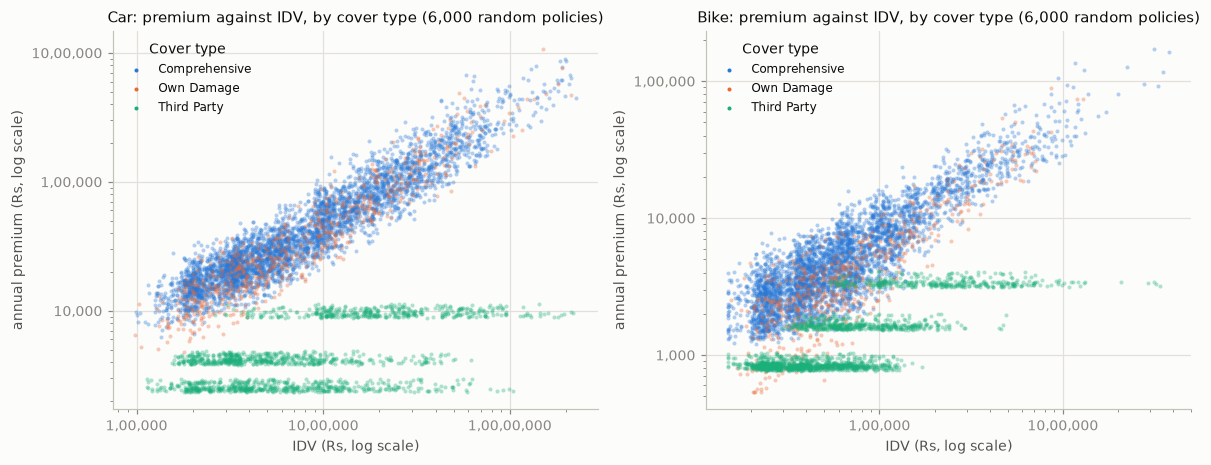

In [4]:
by_cover = []
for kind in quote.KINDS:
    for cover, group in data[kind].groupby("policy_type"):
        by_cover.append({"vehicle": kind, "cover type": cover, "rows": f"{len(group):,}",
                         "median premium": inr(group["annual_premium"].median()),
                         "correlation of log IDV and log premium":
                             round(float(np.corrcoef(np.log(group["idv"]), np.log(group["annual_premium"]))[0, 1]), 2)})
display(pd.DataFrame(by_cover).set_index(["vehicle", "cover type"]))

COVER_COLOURS = {"Comprehensive": BLUE, "Own Damage": ORANGE, "Third Party": AQUA}
figure, axes = plt.subplots(1, 2, figsize=(11, 4.3))
for axis, kind in zip(axes, quote.KINDS):
    df = data[kind].sample(6000, random_state=0)
    for cover, colour in COVER_COLOURS.items():
        part = df[df["policy_type"] == cover]
        axis.scatter(part["idv"], part["annual_premium"], s=7, alpha=0.35, color=colour, linewidths=0, label=cover)
    axis.set_xscale("log")
    axis.set_yscale("log")
    axis.xaxis.set_major_formatter(RUPEES)
    axis.yaxis.set_major_formatter(RUPEES)
    axis.set_xlabel("IDV (Rs, log scale)")
    axis.set_ylabel("annual premium (Rs, log scale)")
    axis.set_title(f"{kind.capitalize()}: premium against IDV, by cover type (6,000 random policies)")
    tidy(axis, "both")
    legend = axis.legend(title="Cover type", frameon=False, loc="upper left")
    for handle in legend.legend_handles:
        handle.set_alpha(1)
figure.tight_layout()
plt.show()

For Comprehensive and Own Damage policies the premium rises with the IDV. A **Third Party** premium does not: it sits on a few
flat levels, one for each group of engine sizes, and inside a group the IDV makes no difference (the last column below is
close to 0). Electric vehicles have no engine size; they are priced like the smallest group.

In [5]:
SLABS = {"car": ([-1, 1000, 1500, 10_000], ["up to 1000 cc (and electric)", "1000 to 1500 cc", "above 1500 cc"]),
         "bike": ([-1, 150, 350, 10_000], ["up to 150 cc (and electric)", "150 to 350 cc", "above 350 cc"])}
slab_rows = []
for kind in quote.KINDS:
    third = data[kind][data[kind]["policy_type"] == "Third Party"].copy()
    bins, names = SLABS[kind]
    third["engine size"] = pd.cut(third["engine_cc"], bins=bins, labels=names)
    for name, group in third.groupby("engine size", observed=True):
        slab_rows.append({"vehicle": kind, "Third Party, engine size": name, "rows": f"{len(group):,}",
                          "median premium": inr(group["annual_premium"].median()),
                          "correlation of log IDV and log premium":
                              round(float(np.corrcoef(np.log(group["idv"]), np.log(group["annual_premium"]))[0, 1]), 2)})
display(pd.DataFrame(slab_rows).set_index(["vehicle", "Third Party, engine size"]))

rows median premium  correlation of log IDV and log premium
vehicle Third Party, engine size                                                                   
car     up to 1000 cc (and electric)  18,959         ₹2,546                                   -0.00
        1000 to 1500 cc               17,096         ₹4,153                                   -0.01
        above 1500 cc                 13,932         ₹9,610                                    0.00
bike    up to 150 cc (and electric)   24,268           ₹836                                   -0.06
        150 to 350 cc                 11,354         ₹1,638                                    0.00
        above 350 cc                   9,311         ₹3,359                                    0.02

## 2. Five columns we must not use
The files also hold the **pieces of the premium**: `od_premium_before_ncb`, `ncb_discount_amount`, `tp_premium`,
`addon_premium` and `gst_amount`. A customer who asks for a quote knows none of them - they are worked out *from* the
quote. A model that may use them looks better in a notebook than it can ever be on the web page. That mistake is called
**data leakage**. Section 7 measures how much better it would look. First, how closely are these columns tied to the premium?

In [6]:
PARTS = ["od_premium_before_ncb", "ncb_discount_amount", "tp_premium", "addon_premium", "gst_amount"]
parts = {kind: pd.read_csv(quote.raw_path(kind), usecols=["record_id", "annual_premium"] + PARTS) for kind in quote.KINDS}
link = pd.DataFrame({kind: frame[PARTS + ["annual_premium"]].corr()["annual_premium"].drop("annual_premium")
                     for kind, frame in parts.items()})
display(link.round(4).rename_axis("correlation with the premium"))
share = parts["car"]["gst_amount"] / parts["car"]["annual_premium"]
print(f"car: gst_amount is between {100 * share.quantile(0.01):.1f} % and {100 * share.quantile(0.99):.1f} % of the premium "
      f"(middle value {100 * share.median():.2f} %)")

,car,bike
correlation with the premium,,
od_premium_before_ncb,0.7842,0.7828
ncb_discount_amount,0.5160,0.5453
tp_premium,0.4046,0.5426
addon_premium,0.0229,0.0733
gst_amount,0.9994,0.9994


car: gst_amount is between 14.5 % and 16.0 % of the premium (middle value 15.25 %)


`gst_amount` is almost a copy of the premium. If GST is 18 % of the price before GST, it is 18 / 118 = 15.25 % of the price
*including* GST - the middle value above. But the share is not always 15.25 %: it moves between about 14.5 % and 16 %. So the
recorded premium is not exactly "price + 18 % GST". The next picture divides the recorded premium by "price + 18 % GST"
(the price worked out from `gst_amount`). If the two agreed, every policy would sit at 1.00.

 car: for 98 % of the policies the recorded premium is between 0.951 and 1.049 times 'price + 18 % GST'; typical gap 2.5 %; 0 of 200,000 policies lie outside the picture
bike: for 98 % of the policies the recorded premium is between 0.951 and 1.049 times 'price + 18 % GST'; typical gap 2.5 %; 36 of 150,000 policies lie outside the picture


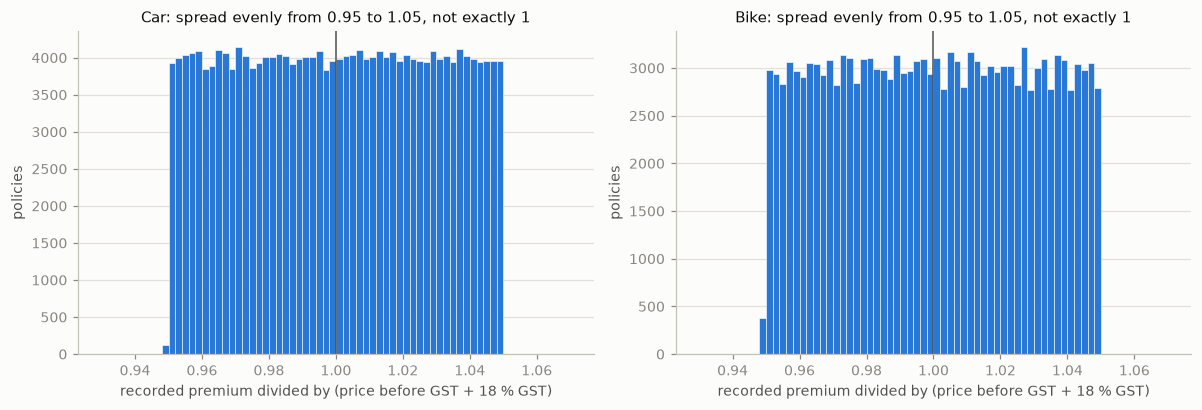

In [7]:
GST_SHARE = 0.18 / 1.18
figure, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for axis, kind in zip(axes, quote.KINDS):
    ratio = (parts[kind]["annual_premium"] * GST_SHARE / parts[kind]["gst_amount"]).replace([np.inf, -np.inf], np.nan).dropna()
    low, high = ratio.quantile([0.01, 0.99])
    outside = int(((ratio < 0.93) | (ratio > 1.07)).sum())
    print(f"{kind:>4}: for 98 % of the policies the recorded premium is between {low:.3f} and {high:.3f} times "
          f"'price + 18 % GST'; typical gap {100 * np.abs(ratio - 1).median():.1f} %; "
          f"{outside} of {len(ratio):,} policies lie outside the picture")
    axis.hist(ratio, bins=70, range=(0.93, 1.07), color=BLUE, edgecolor=SURFACE, linewidth=0.4)
    axis.axvline(1, color=INK2, linewidth=1)
    axis.set_xlabel("recorded premium divided by (price before GST + 18 % GST)")
    axis.set_ylabel("policies")
    axis.set_title(f"{kind.capitalize()}: spread evenly from 0.95 to 1.05, not exactly 1")
    tidy(axis, "y")
figure.tight_layout()
plt.show()

The picture is a flat block between 0.95 and 1.05. It looks as if the dataset adds a random variation of up to 5 % in either
direction to every premium, after the GST was worked out. A model cannot predict random variation, so a typical error of
about 2.5 % is the best any model can reach on this data. Section 7 confirms this.

## 3. Train / test split
80 % of the rows teach the model; 20 % are kept back and used only to measure the result (`random_state=42`, so the
split is the same on every run). A model graded on rows it has already seen would look better than it really is.

In [8]:
train_rows, X_train, y_train, X_test, y_test = {}, {}, {}, {}, {}
for kind in quote.KINDS:
    train, test = quote.split_data(data[kind])
    train_rows[kind] = train
    X_train[kind], y_train[kind] = quote.xy(train, kind)
    X_test[kind], y_test[kind] = quote.xy(test, kind)
    print(f"{kind:>4}: {len(train):,} rows to learn from, {len(test):,} rows held back for testing")

 car: 159,995 rows to learn from, 39,999 rows held back for testing
bike: 119,999 rows to learn from, 30,000 rows held back for testing


## 4. Feature engineering
The quote form asks only a few simple questions. `QuoteFeatures` (in `acko/quote.py`) turns the answers into the numbers
the model learns from:

| From the form | Becomes |
|---|---|
| year of manufacture | vehicle age = 2025 - year (the data was priced in 2025) |
| city | city risk score (a look-up table learned from the training rows) |
| make + model + fuel | engine size and body type (look-up tables, so the customer does not need to know them) |
| cover type, fuel, body type, bike use | a code number for each value |
| IDV, NCB, add-ons, past claims, driver age | passed on unchanged (a skipped optional answer gets the typical value) |

The look-up tables are learned in `fit()` from the **training rows only**; `transform()` then needs nothing but the form's answers.
This is the code of `transform()`:

In [9]:
print(textwrap.dedent(inspect.getsource(quote.QuoteFeatures.transform)))

def transform(self, X) -> pd.DataFrame:
    X = pd.DataFrame(X).copy()
    for column, value in self.defaults_.items():            # optional answers the customer skipped
        if column not in X.columns:
            X[column] = value
    keys = list(zip(X["vehicle_make"], X["vehicle_model"], X["fuel_type"]))
    engine = [self.engine_.get(k, self.engine_by_model_.get(k[:2], self.engine_default_)) for k in keys]
    segment = pd.Series([self.segment_.get(k, self.segment_by_model_.get(k[:2], self.segment_default_))
                         for k in keys], index=X.index)
    out = pd.DataFrame(index=X.index)
    out["idv"] = X["idv"].astype(float)
    out["city_risk_score"] = X["city"].map(self.city_risk_).fillna(self.risk_default_).astype(float)
    out["vehicle_age_years"] = (PRICING_YEAR - X["manufacturing_year"].astype(float)).clip(lower=0)
    out["ncb_percent"] = X["ncb_percent"].astype(float)
    out["engine_cc"] = np.asarray(engine, dtype=float)
    out["num_addons"] = X["num_a

In [10]:
kind = "car"
features = quote.QuoteFeatures(kind).fit(X_train[kind])
shown = X_test[kind].head(5)
print("What the quote form collects (5 test policies):")
display(shown[quote.input_columns(kind)[:7]])
print("What the model sees:")
display(features.transform(shown).round(2))
risk = pd.Series(features.city_risk_).sort_values()
print("City risk look-up, learned from the training rows (three lowest and three highest cities):")
display(pd.concat([risk.head(3), risk.tail(3)]).rename("city risk score").to_frame())

# At quote time the form has no city risk, engine size or body type column. transform() must give the same numbers without them.
form_only = shown[quote.input_columns(kind)]
same = features.transform(form_only).equals(features.transform(shown))
print("transform() gives the same numbers from the form's answers alone:", same)
assert same

What the quote form collects (5 test policies):


,vehicle_make,vehicle_model,fuel_type,manufacturing_year,city,idv,ncb_percent
147653,Renault,Kwid,CNG,2013,Karnal,149370,25
158826,Maruti Suzuki,Celerio,Petrol,2015,Akola,228199,0
54937,BMW,7 Series,Petrol,2014,Bareilly,6330771,50
49694,MG,Hector Plus,Petrol,2010,Mangalore,475451,35
86254,Honda,CR-V,Diesel,2009,Imphal,998608,35


What the model sees:


,idv,city_risk_score,vehicle_age_years,ncb_percent,engine_cc,policy_type,num_addons,claim_history_count,customer_age,fuel_type,segment
147653,149370.0,0.90,12.0,25.0,999.0,0.0,1.0,0.0,75.0,0.0,1.0
158826,228199.0,0.88,10.0,0.0,998.0,0.0,0.0,3.0,22.0,5.0,1.0
54937,6330771.0,1.12,11.0,50.0,2998.0,2.0,4.0,0.0,30.0,5.0,4.0
49694,475451.0,0.95,15.0,35.0,1451.0,0.0,1.0,1.0,37.0,5.0,5.0
86254,998608.0,0.85,16.0,35.0,1498.0,0.0,0.0,0.0,40.0,1.0,5.0


City risk look-up, learned from the training rows (three lowest and three highest cities):


,city risk score
Aizawl,0.82
Kohima,0.82
Itanagar,0.82
Bengaluru,1.45
Delhi,1.50
Mumbai,1.50


transform() gives the same numbers from the form's answers alone: True


## 5. Training
One model for cars and one for bikes (their prices behave differently). Each is a **gradient boosting** regressor
(`HistGradientBoostingRegressor`): many small decision trees, each one correcting the mistakes of the trees before it.
The model learns the **logarithm of the premium**. A premium grows by percentages (twice the IDV, roughly twice the
premium), and on a log scale percentage effects simply add up - which is also what makes the SHAP explanation exact.
Training stops by itself when 10 % of the training rows, kept aside inside the training data, show no more gain.

In [11]:
print(inspect.getsource(quote.build_model))

def build_model(kind: str) -> TransformedTargetRegressor:
    """Feature engineering + gradient boosting. The model learns log(premium), predict() gives rupees again.

    Learning the logarithm fits a price that grows by percentages (more IDV = a higher premium in proportion),
    and it makes the SHAP explanation add up as 'percent steps' that multiply: IDV +30%, city +5%, NCB -20% ...
    """
    steps = [("features", QuoteFeatures(kind)),
             ("model", HistGradientBoostingRegressor(max_iter=MAX_ROUNDS, learning_rate=0.1, early_stopping=True,
                                                     random_state=0))]
    return TransformedTargetRegressor(regressor=Pipeline(steps), func=np.log, inverse_func=np.exp, check_inverse=False)



In [12]:
models, rounds = {}, {}
for kind in quote.KINDS:
    started = time.time()
    models[kind] = quote.build_model(kind).fit(X_train[kind], y_train[kind])
    rounds[kind] = models[kind].regressor_.named_steps["model"].n_iter_
    print(f"{kind:>4}: trained in {time.time() - started:.0f} s, {rounds[kind]} boosting rounds")

 car: trained in 10 s, 765 boosting rounds


bike: trained in 5 s, 541 boosting rounds


## 6. Results against the brief
The brief asks for **R2 above 0.85** and **RMSE within Rs 2,000** on held-out data. The quote form accepts an IDV up to
Rs 10,00,000, so the brief's targets are checked on the test rows in that range. The data also holds very expensive
vehicles (the dearest car is worth over 2 crore): for them a few percent of error is many rupees, so they are listed separately.

In [13]:
TARGET_R2, TARGET_RMSE = 0.85, 2000
metrics = {kind: quote.evaluate(models[kind], X_test[kind], y_test[kind]) for kind in quote.KINDS}
rows = []
for kind in quote.KINDS:
    for label, key in (("IDV up to Rs 10,00,000 (the form's range)", "form_range"), ("all test rows, any IDV", "all")):
        m = metrics[kind][key]
        rows.append({"vehicle": kind, "test rows": label, "rows": f"{m['n']:,}", "R2": round(m["r2"], 4),
                     "RMSE": inr(m["rmse"]), "MAE": inr(m["mae"]), "typical error": f"{m['median_pct_error']:.1f} %"})
display(pd.DataFrame(rows).set_index(["vehicle", "test rows"]))

for kind in quote.KINDS:
    m = metrics[kind]["form_range"]
    met = m["r2"] > TARGET_R2 and m["rmse"] <= TARGET_RMSE
    print(f"{kind:>4}: R2 {m['r2']:.4f} (needs > {TARGET_R2})   RMSE {inr(m['rmse'])} (needs <= {inr(TARGET_RMSE)})   "
          f"-> {'MET' if met else 'NOT MET'}")
    assert met, f"The {kind} model misses the targets of the brief"

rows      R2    RMSE     MAE typical error
vehicle test rows                                                                              
car     IDV up to Rs 10,00,000 (the form's range)  24,145  0.9912  ₹1,323    ₹882         3.3 %
        all test rows, any IDV                     39,999  0.9965  ₹4,780  ₹1,900         3.1 %
bike    IDV up to Rs 10,00,000 (the form's range)  29,733  0.9939    ₹539    ₹292         3.6 %
        all test rows, any IDV                     30,000  0.9933    ₹702    ₹314         3.6 %

 car: R2 0.9912 (needs > 0.85)   RMSE ₹1,323 (needs <= ₹2,000)   -> MET
bike: R2 0.9939 (needs > 0.85)   RMSE ₹539 (needs <= ₹2,000)   -> MET


In [14]:
for kind in quote.KINDS:
    bands = pd.DataFrame(metrics[kind]["bands"])
    table = pd.DataFrame({"IDV band": bands["label"], "test rows": bands["n"].map("{:,}".format), "R2": bands["r2"].round(4),
                          "RMSE": bands["rmse"].map(inr), "typical error": bands["median_pct_error"].map("{:.1f} %".format)})
    print(f"{kind.capitalize()}: error by IDV band")
    display(table.set_index("IDV band"))

Car: error by IDV band


,test rows,R2,RMSE,typical error
IDV band,,,,
1 to 3 lakh,"7,590",0.9742,"₹1,119",3.8 %
3 to 6 lakh,"10,626",0.9871,"₹1,280",3.3 %
6 to 10 lakh,"5,912",0.9928,"₹1,610",3.0 %
10 to 25 lakh,"8,925",0.9951,"₹2,799",2.8 %
above 25 lakh,"6,929",0.9943,"₹10,757",2.8 %


Bike: error by IDV band


,test rows,R2,RMSE,typical error
IDV band,,,,
up to 1 lakh,"22,059",0.9688,₹379,3.9 %
1 to 3 lakh,"5,784",0.9911,₹579,3.2 %
3 to 6 lakh,"1,423",0.9921,"₹1,176",3.1 %
6 to 10 lakh,467,0.9907,"₹1,839",2.9 %
10 to 25 lakh,246,0.9816,"₹4,597",3.6 %


For a customer the question is simpler: how many quotes are close to the real premium?

In [15]:
close_rows = []
for kind in quote.KINDS:
    inside = (X_test[kind]["idv"] <= quote.FORM_IDV_MAX).to_numpy()
    gap = np.abs(np.asarray(models[kind].predict(X_test[kind]), dtype=float)[inside]
                 / np.asarray(y_test[kind], dtype=float)[inside] - 1)
    close_rows.append({"vehicle": kind, "test rows": f"{inside.sum():,}", **{f"within {limit} %": f"{100 * (gap <= limit / 100).mean():.1f} %"
                                                                             for limit in (5, 10, 25)}})
display(pd.DataFrame(close_rows).set_index("vehicle"))

,test rows,within 5 %,within 10 %,within 25 %
vehicle,,,,
car,"24,145",69.8 %,91.7 %,99.8 %
bike,"29,733",64.3 %,84.0 %,97.8 %


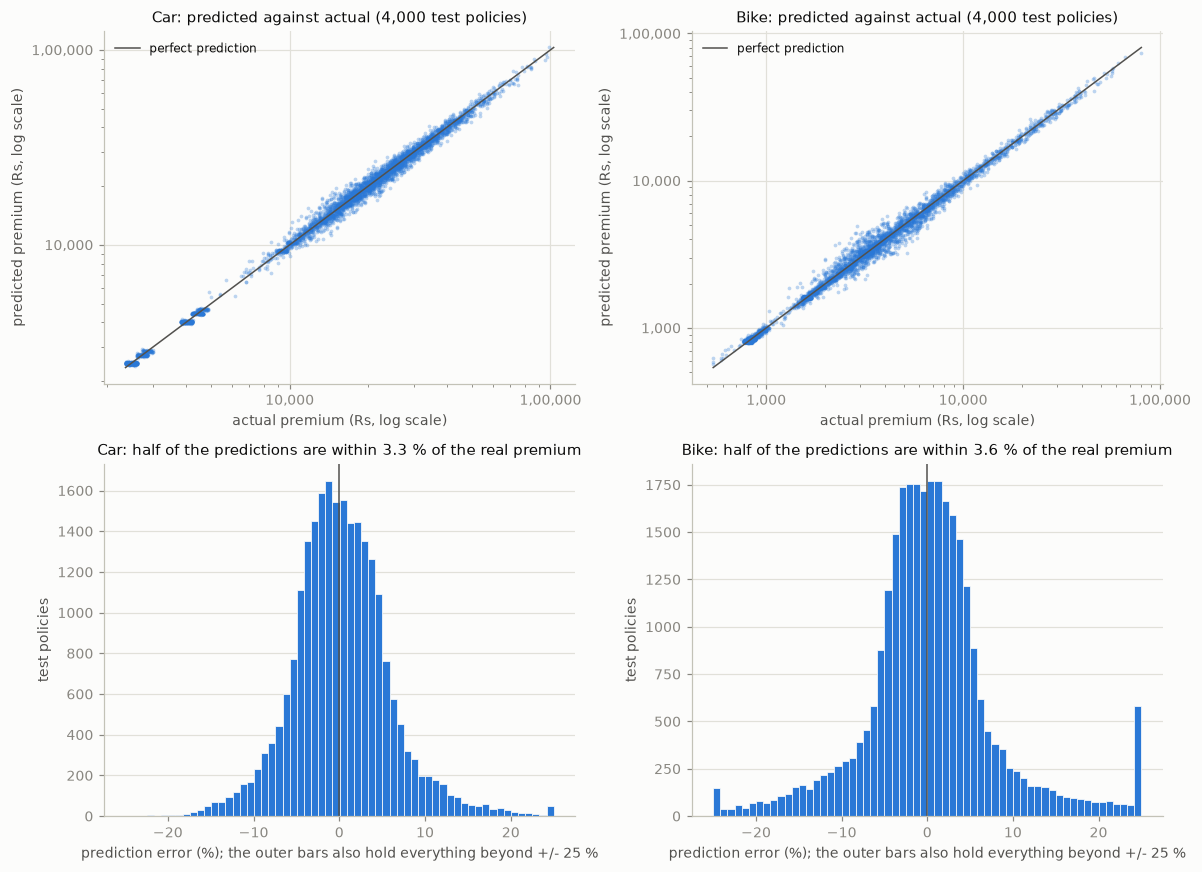

In [16]:
figure, axes = plt.subplots(2, 2, figsize=(11, 8))
for column, kind in enumerate(quote.KINDS):
    X, actual = X_test[kind], np.asarray(y_test[kind], dtype=float)
    inside = (X["idv"] <= quote.FORM_IDV_MAX).to_numpy()
    predicted = np.asarray(models[kind].predict(X), dtype=float)
    pick = np.random.default_rng(0).choice(np.flatnonzero(inside), size=min(4000, int(inside.sum())), replace=False)
    axis = axes[0, column]
    axis.scatter(actual[pick], predicted[pick], s=6, alpha=0.3, color=BLUE, linewidths=0)
    limits = [min(actual[pick].min(), predicted[pick].min()), max(actual[pick].max(), predicted[pick].max())]
    axis.plot(limits, limits, color=INK2, linewidth=1, label="perfect prediction")
    axis.set_xscale("log")
    axis.set_yscale("log")
    axis.xaxis.set_major_formatter(RUPEES)
    axis.yaxis.set_major_formatter(RUPEES)
    axis.set_xlabel("actual premium (Rs, log scale)")
    axis.set_ylabel("predicted premium (Rs, log scale)")
    axis.set_title(f"{kind.capitalize()}: predicted against actual (4,000 test policies)")
    tidy(axis, "both")
    axis.legend(frameon=False, loc="upper left")
    error = 100 * (predicted[inside] / actual[inside] - 1)
    axis = axes[1, column]
    axis.hist(np.clip(error, -25, 25), bins=60, color=BLUE, edgecolor=SURFACE, linewidth=0.5)
    axis.axvline(0, color=INK2, linewidth=1)
    axis.set_xlabel("prediction error (%); the outer bars also hold everything beyond +/- 25 %")
    axis.set_ylabel("test policies")
    axis.set_title(f"{kind.capitalize()}: half of the predictions are within {np.median(np.abs(error)):.1f} % of the real premium")
    tidy(axis, "y")
figure.tight_layout()
plt.show()

## 7. What the five columns would do if the model could see them
To see why they are off limits, train the same model once more with `gst_amount` added to its inputs, and once with all five
columns. Same split, same settings, same test rows - only the inputs differ. The last row needs no model at all: it takes
`gst_amount`, works out the price before GST (`gst_amount / 0.18`) and adds the GST.

In [17]:
extra = {}
for kind in quote.KINDS:
    raw = parts[kind].drop_duplicates("record_id")[["record_id"] + PARTS]
    extra[kind] = data[kind][["record_id"]].merge(raw, on="record_id", how="left")[PARTS]      # same rows, same order as data[kind]


def fit_and_score(kind, columns):
    """The real model settings, trained with some of the five leaking columns added to the features."""
    features = quote.QuoteFeatures(kind).fit(X_train[kind])
    learn_x, check_x = features.transform(X_train[kind]), features.transform(X_test[kind])
    for name in columns:
        learn_x[name] = extra[kind].loc[train_rows[kind].index, name].to_numpy()
        check_x[name] = extra[kind].loc[X_test[kind].index, name].to_numpy()
    booster = HistGradientBoostingRegressor(max_iter=quote.MAX_ROUNDS, learning_rate=0.1, early_stopping=True, random_state=0)
    booster.fit(learn_x, np.log(y_train[kind]))
    inside = (check_x["idv"] <= quote.FORM_IDV_MAX).to_numpy()
    return quote.score(np.asarray(y_test[kind], dtype=float)[inside], np.exp(booster.predict(check_x))[inside])


leak_rows = []
for kind in quote.KINDS:
    inside = (X_test[kind]["idv"] <= quote.FORM_IDV_MAX).to_numpy()
    price_and_gst = (extra[kind].loc[X_test[kind].index, "gst_amount"] / 0.18 * 1.18).to_numpy()
    results = [("the quote form's answers only (our model)", metrics[kind]["form_range"]),
               ("... plus gst_amount", fit_and_score(kind, ["gst_amount"])),
               ("... plus all five columns", fit_and_score(kind, PARTS)),
               ("no model: price + 18 % GST worked out from gst_amount",
                quote.score(np.asarray(y_test[kind], dtype=float)[inside], price_and_gst[inside]))]
    for label, result in results:
        leak_rows.append({"vehicle": kind, "what is used": label, "R2": round(result["r2"], 4), "RMSE": inr(result["rmse"]),
                          "typical error": f"{result['median_pct_error']:.1f} %"})
display(pd.DataFrame(leak_rows).set_index(["vehicle", "what is used"]))

R2    RMSE typical error
vehicle what is used                                                                    
car     the quote form's answers only (our model)           0.9912  ₹1,323         3.3 %
        ... plus gst_amount                                 0.9974    ₹720         2.5 %
        ... plus all five columns                           0.9974    ₹719         2.5 %
        no model: price + 18 % GST worked out from gst_...  0.9975    ₹707         2.5 %
bike    the quote form's answers only (our model)           0.9939    ₹539         3.6 %
        ... plus gst_amount                                 0.9969    ₹384         2.5 %
        ... plus all five columns                           0.9974    ₹353         2.5 %
        no model: price + 18 % GST worked out from gst_...  0.9986    ₹255         2.5 %

**Reading the table.** With the leaking columns the typical error falls to about 2.5 % and the RMSE falls clearly. 2.5 % is exactly
the random variation found in section 2, so it is as good as any model can get on this data - even one that cheats. The model
that uses only the quote form's answers is within about one percentage point of that limit.

But the models with the leaking columns can never run on the web page: a customer who asks for a quote cannot tell us the GST,
because the GST is worked out from the quote. That is why the project's model uses **only answers the quote form can collect**
(plus typical values for the optional questions).

## 8. Why gradient boosting?
A fair comparison on the same test rows (IDV up to the form's limit): (1) guess the middle premium for everybody,
(2) a **linear regression** on the same features, which can only learn straight-line rules, (3) our model.

In [18]:
baseline_rows = []
for kind in quote.KINDS:
    for b in quote.compare_baselines(kind, X_train[kind], y_train[kind], X_test[kind], y_test[kind], models[kind]):
        baseline_rows.append({"vehicle": kind, "method": b["name"], "R2": round(b["r2"], 4), "RMSE": inr(b["rmse"])})
display(pd.DataFrame(baseline_rows).set_index(["vehicle", "method"]))

R2     RMSE
vehicle method                                                   
car     Guess the median premium for everyone    -0.0713  ₹14,588
        Linear regression (straight-line rules)   0.6219   ₹8,666
        Gradient boosting (this project's model)  0.9912   ₹1,323
bike    Guess the median premium for everyone    -0.0855   ₹7,216
        Linear regression (straight-line rules)   0.8307   ₹2,850
        Gradient boosting (this project's model)  0.9939     ₹539

The premium is not a straight-line function of the inputs. Section 1 shows an example: the IDV changes a Comprehensive premium
a lot, but a Third Party premium not at all (that one depends on the engine size). A rule such as "the IDV matters, except
for third-party cover" is easy for decision trees and impossible for a single straight line.

## 9. Which factors matter? Take one away at a time
A simple experiment: train the model again **without one factor** and see how much worse it gets. A factor the model really
needs makes the error jump; a factor that other factors already explain changes almost nothing.
To keep it quick, the experiment uses 60,000 of the training rows (48,000 to learn from, 12,000 to check). The test rows are not touched.
The model settings are the same as above. The factors are the ones shown on the web page (`quote.FACTORS`); for example
"Vehicle type" is engine size + body type + fuel type together.

In [19]:
def take_one_away(kind):
    """Error on check policies when the model is trained without each factor in turn (first row: with all of them)."""
    pool = train_rows[kind].sample(60_000, random_state=1)
    learn, check = train_test_split(pool, test_size=0.2, random_state=1)
    X_learn, X_check = quote.xy(learn, kind)[0], quote.xy(check, kind)[0]
    features = quote.QuoteFeatures(kind).fit(X_learn)
    learn_x, check_x = features.transform(X_learn), features.transform(X_check)
    inside = (check_x["idv"] <= quote.FORM_IDV_MAX).to_numpy()
    actual = check["annual_premium"].to_numpy(dtype=float)[inside]

    def error_without(columns):
        keep = [name for name in learn_x.columns if name not in columns]
        booster = HistGradientBoostingRegressor(max_iter=quote.MAX_ROUNDS, learning_rate=0.1, early_stopping=True, random_state=0)
        booster.fit(learn_x[keep], np.log(learn["annual_premium"]))
        return quote.score(actual, np.exp(booster.predict(check_x[keep]))[inside])

    rows = [{"left out": "nothing (all factors)", "level": "all", **error_without([])}]
    for key, label, columns in quote.FACTORS:
        columns = [name for name in columns if name in learn_x.columns]
        if columns:
            rows.append({"left out": label, "level": "factor", **error_without(columns)})
    for name in ("engine_cc", "segment", "fuel_type"):
        rows.append({"left out": "only " + quote.COLUMN_LABELS[name].lower(), "level": "column", **error_without([name])})
    return pd.DataFrame(rows)


experiments = {}
for kind in quote.KINDS:
    started = time.time()
    experiments[kind] = take_one_away(kind)
    print(f"{kind:>4}: {len(experiments[kind])} small models trained in {time.time() - started:.0f} s")

 car: 13 small models trained in 18 s


bike: 14 small models trained in 19 s


In [20]:
for kind in quote.KINDS:
    result = experiments[kind]
    base = result.iloc[0]["rmse"]
    table = pd.DataFrame({"left out": result["left out"], "R2": result["r2"].round(4), "RMSE": result["rmse"].map(inr),
                          "error compared with all factors": (result["rmse"] / base).map("{:.2f} x".format)})
    print(f"{kind.capitalize()}: error on 12,000 check policies (IDV up to Rs 10,00,000) when one factor is left out")
    display(table.set_index("left out"))

Car: error on 12,000 check policies (IDV up to Rs 10,00,000) when one factor is left out


,R2,RMSE,error compared with all factors
left out,,,
nothing (all factors),0.9896,"₹1,432",1.00 x
Insured value (IDV),0.5384,"₹9,523",6.65 x
City risk,0.9454,"₹3,275",2.29 x
Vehicle age,0.9813,"₹1,918",1.34 x
No-claim bonus (NCB),0.8926,"₹4,593",3.21 x
Vehicle type,0.9489,"₹3,167",2.21 x
Cover type,0.2728,"₹11,953",8.35 x
Add-ons,0.9655,"₹2,605",1.82 x
Past claims,0.9721,"₹2,342",1.64 x


Bike: error on 12,000 check policies (IDV up to Rs 10,00,000) when one factor is left out


,R2,RMSE,error compared with all factors
left out,,,
nothing (all factors),0.9930,₹585,1.00 x
Insured value (IDV),0.9836,₹896,1.53 x
City risk,0.9652,"₹1,306",2.23 x
Vehicle age,0.9908,₹672,1.15 x
No-claim bonus (NCB),0.9381,"₹1,741",2.97 x
Vehicle type,0.9806,₹975,1.67 x
Cover type,0.5290,"₹4,803",8.20 x
Add-ons,0.9788,"₹1,018",1.74 x
Past claims,0.9873,₹787,1.34 x


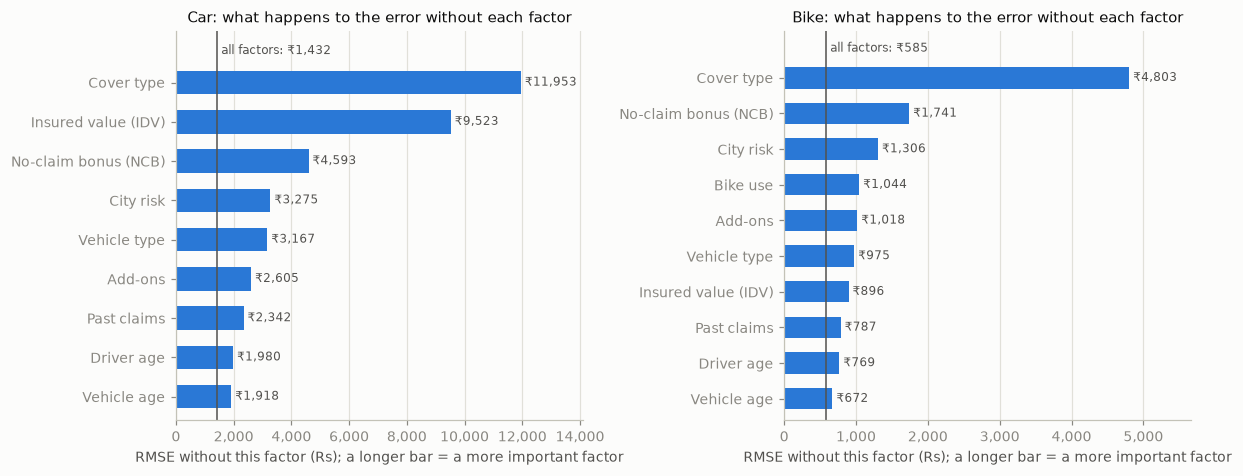

In [21]:
figure, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for axis, kind in zip(axes, quote.KINDS):
    result = experiments[kind]
    base = result.iloc[0]["rmse"]
    factors = result[result["level"] == "factor"].sort_values("rmse")
    axis.barh(factors["left out"], factors["rmse"], color=BLUE, height=0.6)
    axis.axvline(base, color=INK2, linewidth=1)
    for position, value in enumerate(factors["rmse"]):
        axis.text(value, position, " " + inr(value), va="center", fontsize=8, color=INK2)
    axis.text(base, len(factors) - 0.35, " all factors: " + inr(base), va="bottom", fontsize=8, color=INK2)
    axis.set_ylim(-0.6, len(factors) + 0.3)
    axis.xaxis.set_major_formatter(RUPEES)
    axis.set_xlim(0, factors["rmse"].max() * 1.18)
    axis.set_xlabel("RMSE without this factor (Rs); a longer bar = a more important factor")
    axis.set_title(f"{kind.capitalize()}: what happens to the error without each factor")
    tidy(axis, "x")
figure.tight_layout()
plt.show()

**Reading the results.** Every factor helps: leaving out any one of them raises the error. The **cover type** matters most,
for cars and for bikes (a third-party policy costs far less than a comprehensive one). For cars the **IDV** comes next,
then **NCB**; for bikes **NCB** and the **city** follow the cover type. The last rows of each table split "Vehicle type" into its
columns: the **fuel type on its own** changes the error by almost nothing, because engine size and body type already tell the
model what the fuel type could.

This experiment shows what the model *needs*. Section 10 shows how it *uses* each factor.

## 10. SHAP: why does the model give this premium?
SHAP splits the difference between a **typical premium** and the premium of one policy among the factors. The model works
on the logarithm of the premium, so the SHAP values are exact "percent steps" that multiply; `quote.explain_frame` turns them
into rupees that add up exactly to the quote. The brief asks for a SHAP chart with **IDV, city risk, vehicle age and NCB**;
these four are drawn in blue below.

In [22]:
explainers = {kind: quote.make_explainer(models[kind]) for kind in quote.KINDS}
samples = {kind: X_test[kind].sample(3000, random_state=0) for kind in quote.KINDS}
shap_data = {}
for kind in quote.KINDS:
    started = time.time()
    shap_data[kind] = quote.grouped_effects(models[kind], samples[kind], explainers[kind])     # (factor effects, table, SHAP values)
    print(f"{kind:>4}: SHAP values for {len(samples[kind]):,} test policies in {time.time() - started:.0f} s")

 car: SHAP values for 3,000 test policies in 13 s


bike: SHAP values for 3,000 test policies in 10 s


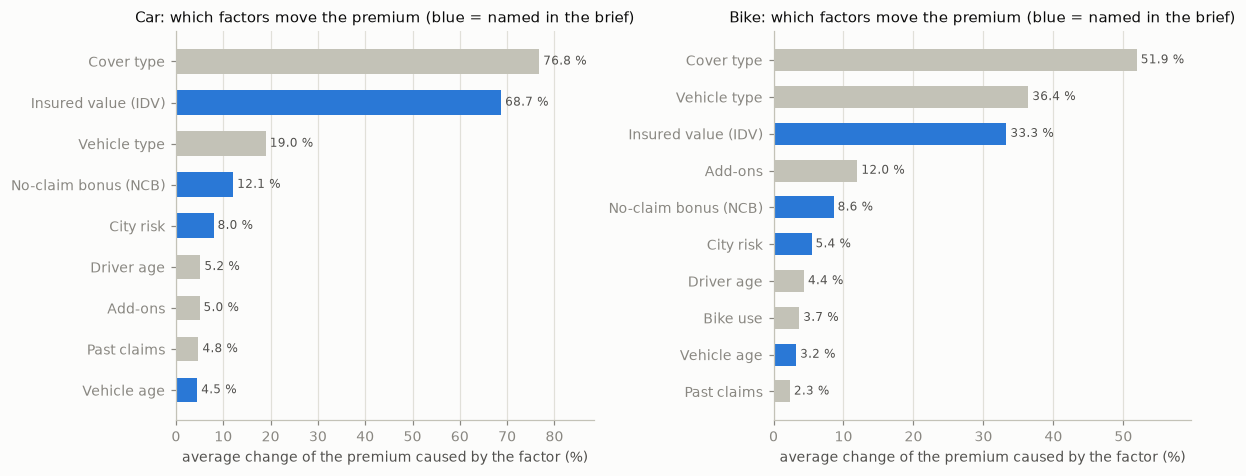

rank average change of the premium
vehicle factor named in the brief                                       
car     Insured value (IDV)         2 of 9                        68.7 %
        City risk                   5 of 9                         8.0 %
        Vehicle age                 9 of 9                         4.5 %
        No-claim bonus (NCB)        4 of 9                        12.1 %
bike    Insured value (IDV)        3 of 10                        33.3 %
        City risk                  6 of 10                         5.4 %
        Vehicle age                9 of 10                         3.2 %
        No-claim bonus (NCB)       5 of 10                         8.6 %

In [23]:
BRIEF_FACTORS = ["Insured value (IDV)", "City risk", "Vehicle age", "No-claim bonus (NCB)"]
figure, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for axis, kind in zip(axes, quote.KINDS):
    effects = shap_data[kind][0][::-1]
    labels, values = [label for label, _ in effects], [value for _, value in effects]
    axis.barh(labels, values, color=[BLUE if label in BRIEF_FACTORS else CONTEXT for label in labels], height=0.6)
    for position, value in enumerate(values):
        axis.text(value, position, f" {value:.1f} %", va="center", fontsize=8, color=INK2)
    axis.set_xlim(0, max(values) * 1.15)
    axis.set_xlabel("average change of the premium caused by the factor (%)")
    axis.set_title(f"{kind.capitalize()}: which factors move the premium (blue = named in the brief)")
    tidy(axis, "x")
figure.tight_layout()
plt.show()

rank_rows = []
for kind in quote.KINDS:
    ranking = [label for label, _ in shap_data[kind][0]]
    effect = dict(shap_data[kind][0])
    for label in BRIEF_FACTORS:
        rank_rows.append({"vehicle": kind, "factor named in the brief": label, "rank": f"{ranking.index(label) + 1} of {len(ranking)}",
                          "average change of the premium": f"{effect[label]:.1f} %"})
display(pd.DataFrame(rank_rows).set_index(["vehicle", "factor named in the brief"]))

**Vehicle age** ranks low for both vehicle types. The likely reason is that the IDV already carries it: an older vehicle is worth
less. A check on the most common car model in the data:

In [24]:
make, model_name, fuel = data["car"].groupby(["vehicle_make", "vehicle_model", "fuel_type"]).size().idxmax()
same_model = data["car"][(data["car"]["vehicle_make"] == make) & (data["car"]["vehicle_model"] == model_name)
                         & (data["car"]["fuel_type"] == fuel)]
age = (quote.PRICING_YEAR - same_model["manufacturing_year"]).clip(lower=0)
print(f"{make} {model_name} ({fuel}), {len(same_model):,} policies: correlation between vehicle age and log IDV = "
      f"{np.corrcoef(age, np.log(same_model['idv']))[0, 1]:.2f}   (-1 = the IDV falls exactly with age)")

Nissan Magnite (Petrol), 5,991 policies: correlation between vehicle age and log IDV = -0.93   (-1 = the IDV falls exactly with age)


The next picture shows every model column (not grouped) for 3,000 test policies. Each dot is one policy; a dot to the right
pushes that policy's premium up, to the left pushes it down; red dots have a high value of the column, blue dots a low one.

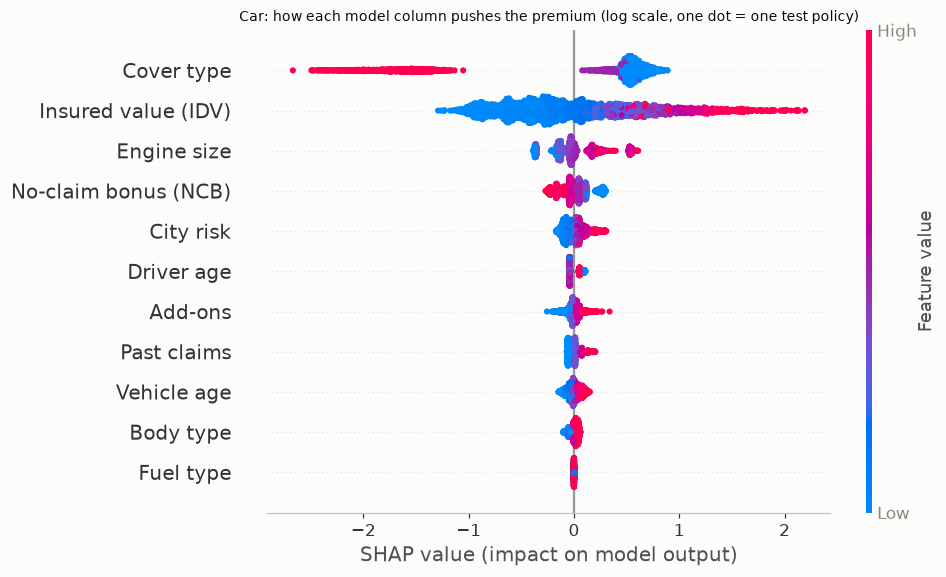

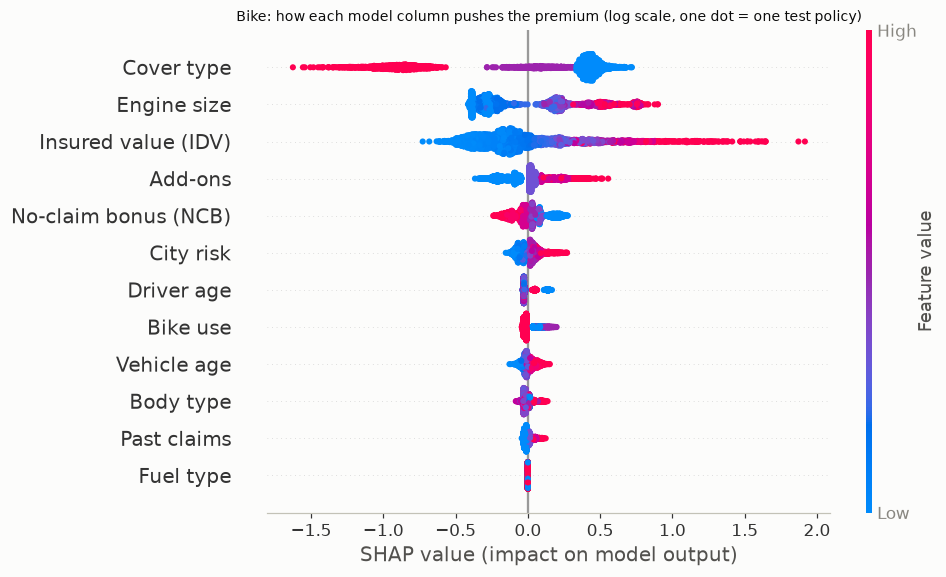

In [25]:
for kind in quote.KINDS:
    _, table, values = shap_data[kind]
    shap.summary_plot(values, table, feature_names=[quote.COLUMN_LABELS[c] for c in table.columns], show=False,
                      max_display=len(table.columns), plot_size=(9, 5.2))
    plt.title(f"{kind.capitalize()}: how each model column pushes the premium (log scale, one dot = one test policy)", fontsize=9)
    plt.show()

### One quote, explained in rupees
A typical policy (its premium is closest to the middle of the test policies inside the form's IDV range), explained the way
the web page explains a quote: start at the typical premium, add or take off rupees for each factor, arrive at the quote.

Car policy: Renault Kwid (Petrol), made 2023, Warangal, IDV ₹4,27,759, NCB 25 %, Comprehensive


,this policy,effect
factor,,
Cover type,Comprehensive,"+₹11,297"
Insured value (IDV),"₹4,27,759","-₹10,614"
Vehicle type,"hatchback, 999 cc, Petrol","-₹4,534"
Add-ons,0 add-ons,"-₹2,140"
Vehicle age,2 years old (made in 2023),"-₹2,118"
No-claim bonus (NCB),25% bonus,"+₹1,272"
Driver age,age 63,"+₹1,119"
City risk,Warangal (risk score 1.05),+₹377
Past claims,1 past claim,+₹143


typical premium ₹23,564 + the effects above = ₹18,365   (the model's quote: ₹18,365)


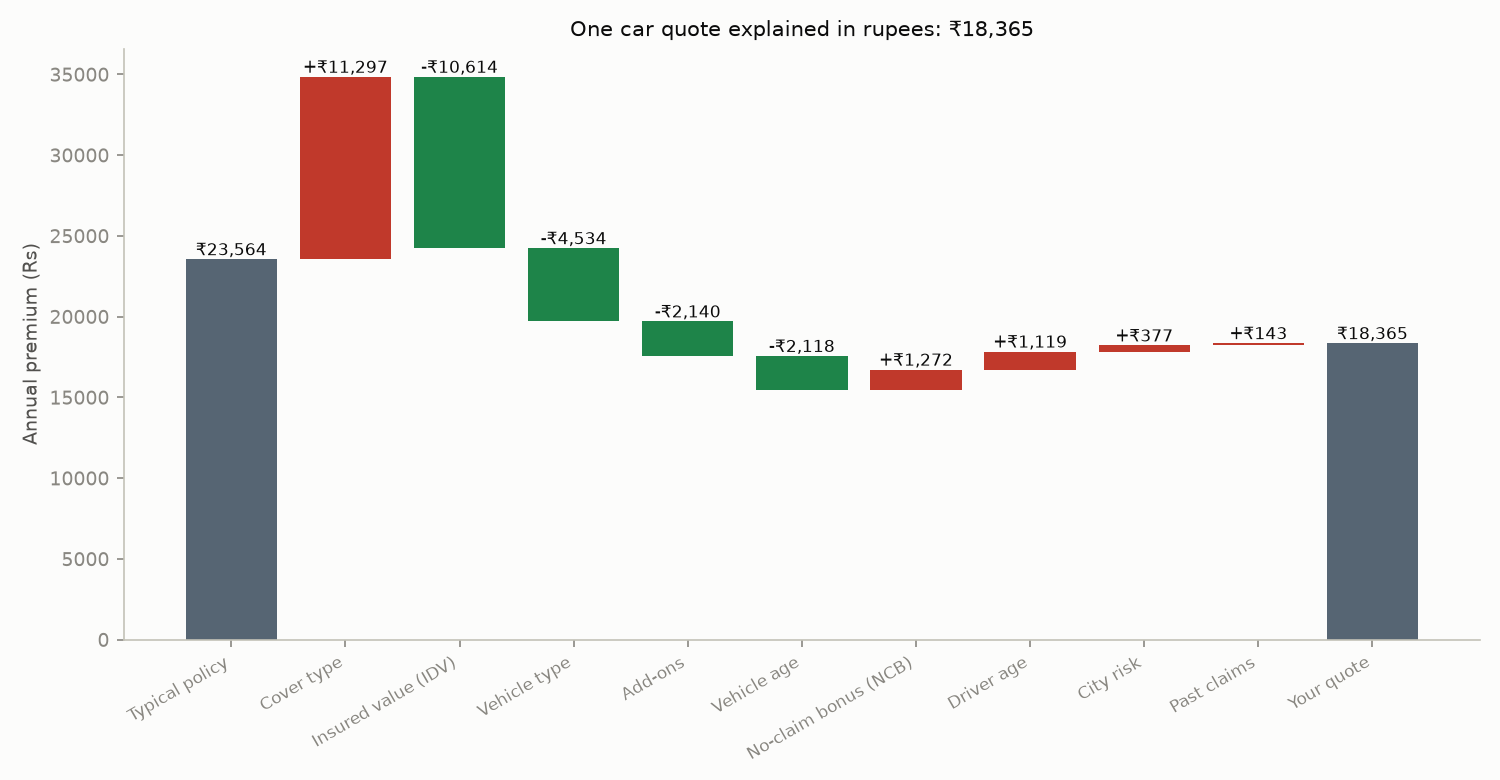

Bike policy: Hero MotoCorp Harley-Davidson X440 (Petrol), made 2013, Raipur, IDV ₹60,952, NCB 35 %, Third Party


,this policy,effect
factor,,
Vehicle type,"cruiser, 440 cc, Petrol","+₹2,463"
Cover type,Third Party,"-₹2,429"
Add-ons,2 add-ons,+₹244
Insured value (IDV),"₹60,952",-₹194
Driver age,age 58,-₹94
No-claim bonus (NCB),35% bonus,-₹43
Bike use,Personal,-₹35
City risk,Raipur (risk score 1.08),+₹34
Vehicle age,12 years old (made in 2013),+₹17


typical premium ₹3,306 + the effects above = ₹3,286   (the model's quote: ₹3,286)


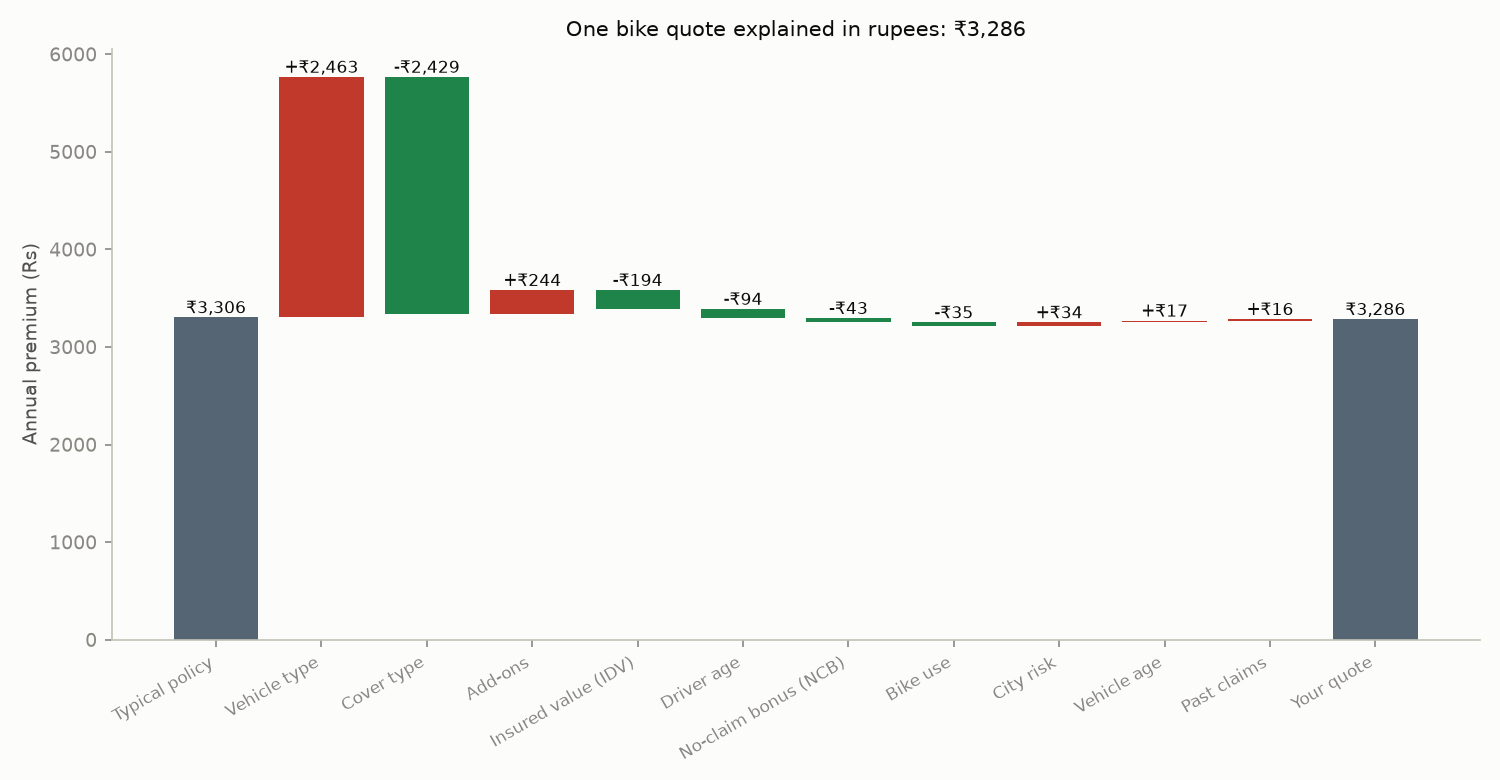

In [26]:
for kind in quote.KINDS:
    inside = X_test[kind][X_test[kind]["idv"] <= quote.FORM_IDV_MAX]
    predicted = models[kind].predict(inside)
    pick = inside.iloc[[int(np.argmin(np.abs(predicted - np.median(predicted))))]]
    q = quote.explain_frame(models[kind], kind, pick, explainers[kind])
    row = pick.iloc[0]
    print(f"{kind.capitalize()} policy: {row['vehicle_make']} {row['vehicle_model']} ({row['fuel_type']}), made {row['manufacturing_year']}, "
          f"{row['city']}, IDV {inr(row['idv'])}, NCB {int(row['ncb_percent'])} %, {row['policy_type']}")
    display(pd.DataFrame([{"factor": f.label, "this policy": f.detail, "effect": ("+" if f.rupees >= 0 else "-") + inr(abs(f.rupees))}
                          for f in q.factors]).set_index("factor"))
    total = q.typical + sum(f.rupees for f in q.factors)
    print(f"typical premium {inr(q.typical)} + the effects above = {inr(total)}   (the model's quote: {inr(q.premium)})")
    assert abs(total - q.premium) < 0.01, "the effects must add up to the quote"
    buffer = io.BytesIO()
    quote.save_waterfall_png(q, buffer, f"One {kind} quote explained in rupees: {inr(q.premium)}")
    matplotlib.use(NOTEBOOK_BACKEND)             # save_waterfall_png switched matplotlib to a file-only backend; switch back
    display(Image(data=buffer.getvalue()))

## 11. The saved model file
`python -m scripts.train_quote` has written `models/quote_model.pkl` (a joblib file). The web page loads exactly this file,
so it must give the same answers as the model trained above and meet the brief on the held-out rows.

In [27]:
try:
    bundle = quote.load_bundle()
except quote.ModelMissing as problem:
    bundle = None
    print(problem)

if bundle is not None:
    print(f"{quote.MODEL_FILE.relative_to(ROOT)}: {quote.MODEL_FILE.stat().st_size / 1e6:.1f} MB, trained {bundle['trained_at']}, "
          f"scikit-learn {bundle['versions']['scikit-learn']}, contents: {', '.join(bundle)}")
    for kind in quote.KINDS:
        saved = bundle["models"][kind]
        difference = float(np.abs(saved.predict(X_test[kind]) - models[kind].predict(X_test[kind])).max())
        m = quote.evaluate(saved, X_test[kind], y_test[kind])["form_range"]
        met = m["r2"] > TARGET_R2 and m["rmse"] <= TARGET_RMSE
        print(f"{kind:>4}: largest difference to the model trained here: Rs {difference:.4f};   saved model on the test rows: "
              f"R2 {m['r2']:.4f}, RMSE {inr(m['rmse'])}  -> {'MET' if met else 'NOT MET'}")
        assert met, f"The saved {kind} model misses the targets of the brief"

models\quote_model.pkl: 2.1 MB, trained 2026-11-13 21:53, scikit-learn 1.9.1, contents: format, trained_at, versions, settings, models, options, metrics, baselines, data_info, importance, rounds


 car: largest difference to the model trained here: Rs 0.0000;   saved model on the test rows: R2 0.9912, RMSE ₹1,323  -> MET


bike: largest difference to the model trained here: Rs 0.0000;   saved model on the test rows: R2 0.9939, RMSE ₹539  -> MET


And one quote asked the way the web page asks it: the saved model through `QuoteEngine`, from the form's answers only.

In [28]:
if bundle is not None:
    engine = quote.QuoteEngine(bundle)
    q = engine.quote("car", "Honda", "City", "Petrol", 2020, "Chennai", 808_000, 0)
    print(f"Honda City (Petrol), 2020, Chennai, IDV {inr(808_000)}, NCB 0 %  ->  premium {inr(q.premium)}  "
          f"(typical premium {inr(q.typical)})")
    for f in q.factors[:4]:
        print(f"   {f.label:<22} {('+' if f.rupees >= 0 else '-') + inr(abs(f.rupees)):>10}   {f.detail}")

Honda City (Petrol), 2020, Chennai, IDV ₹8,08,000, NCB 0 %  ->  premium ₹54,400  (typical premium ₹23,564)
   Cover type               +₹22,757   Comprehensive
   No-claim bonus (NCB)     +₹10,563   0% bonus
   City risk                 +₹9,204   Chennai (risk score 1.40)
   Insured value (IDV)       -₹3,080   ₹8,08,000


## Summary

In [29]:
summary = []
for kind in quote.KINDS:
    m = metrics[kind]["form_range"]
    summary.append({"vehicle": kind, "test rows": f"{m['n']:,}", "R2 (needs > 0.85)": f"{m['r2']:.4f}",
                    "RMSE (needs <= Rs 2,000)": inr(m["rmse"]), "typical error": f"{m['median_pct_error']:.1f} %",
                    "brief met": "yes" if m["r2"] > TARGET_R2 and m["rmse"] <= TARGET_RMSE else "NO"})
display(pd.DataFrame(summary).set_index("vehicle"))
print("SHAP chart with IDV, city risk, vehicle age and NCB: section 10")
print("Model stored as a joblib .pkl file:", quote.MODEL_FILE.relative_to(ROOT) if bundle is not None else "not created yet")
print(f"Run time of this notebook: {(time.time() - STARTED) / 60:.1f} minutes")

,test rows,R2 (needs > 0.85),"RMSE (needs <= Rs 2,000)",typical error,brief met
vehicle,,,,,
car,"24,145",0.9912,"₹1,323",3.3 %,yes
bike,"29,733",0.9939,₹539,3.6 %,yes


SHAP chart with IDV, city risk, vehicle age and NCB: section 10
Model stored as a joblib .pkl file: models\quote_model.pkl
Run time of this notebook: 1.9 minutes


## Limits to be honest about
- The prices in the dataset are synthetic. The model learns the pricing of this dataset, not real Acko prices.
- The recorded premiums carry a random variation of up to 5 % (sections 2 and 7). That sets a limit of about 2.5 % typical error
  for any model; ours is 3.3 % for cars and 3.6 % for bikes.
- The RMSE target is met inside the form's IDV range (up to Rs 10,00,000). For very expensive vehicles the percentage error
  is similar but the rupee error is larger (section 6).
- Vehicle age is counted from 2025, the year the data was priced, not from today's date.
- The brief's lowest IDV for cars is Rs 50,000, but the cheapest car in the data is worth more; below the data the web page
  warns that the estimate is less reliable.
- While the model was being built, a few extra columns (record id, colour, variant, state, previous insurer) were tried and
  compared on the test rows; none lowered the error, so the model does not use them. The test rows therefore helped to make
  that choice. A stricter project would keep a third, untouched set for the final check.
- SHAP explains how the model computes a price, not why a real insurer would charge it.